# Reducción de dimensionalidad: ¿cómo se ven 1,132 partidas en dos dimensiones?

**Visualización de datos y narración de historias** · Héctor Manuel Morán Maldonado

**Proyecto:** *¿En qué minuto se perdió la partida?* — análisis de mis partidas clasificatorias
de League of Legends.

**Actividad:** experimentar con algoritmos de reducción de dimensionalidad para visualizar datos
de más de 4 dimensiones. Los datos del proyecto tienen **20 dimensiones**, así que se usan
directamente (caso 1 de la actividad), con los cuatro algoritmos vistos en clase:
**PCA, LDA, t-SNE y UMAP**.

**Pregunta que guía el notebook:** si cada partida es un punto en un espacio de 20 dimensiones,
¿las victorias y las derrotas forman grupos separados? ¿Y las distintas *formas de perder* que
definí en el proyecto aparecen como grupos, o las partidas forman un continuo?

*Para volver a ejecutarlo:* el notebook vive en la carpeta `LoL_Dimensionalidad/` del repositorio
del proyecto y lee las tablas públicas de `LoL_Datos/` y el código de `LoL_Analisis/scripts/`;
se corre desde esa carpeta (o con `python LoL_Dimensionalidad/scripts/construir_notebook.py`
desde la raíz, que lo ejecuta completo y genera también el PDF).

## 1. Los datos: cada partida es una curva de 20 números

En League of Legends dos equipos de cinco compiten por destruir la base del otro. El **oro** es el
marcador oculto: todo lo bueno que hace un equipo le da oro, y el que tiene más oro suele ir
ganando. Para cada minuto $t$ de cada partida mido la ventaja relativa de mi equipo:

$$v(t) = \frac{\text{oro de mi equipo} - \text{oro del rival}}{\text{oro total de los diez jugadores}} \times 100$$

$v(t) > 0$ significa que mi equipo va ganando en oro; $v(t) < 0$, que va perdiendo. Se usa la
ventaja **relativa** porque 2,000 de oro pesan mucho al inicio (cuando hay poco oro en el mapa) y
casi nada al final.

**Cada partida se representa con el vector** $\big(v(1), v(2), \dots, v(20)\big)$: **20
dimensiones**, una por minuto. Se usan las partidas que duraron al menos 20 minutos (1,132 de las
1,195 de la muestra), para que todas tengan las 20 coordenadas sin rellenar huecos. Los datos
salen de las tablas públicas y anonimizadas del repositorio del proyecto; ninguna contiene
nombres de jugadores.

Cada partida tiene además dos **etiquetas** que *no* entran a los algoritmos no supervisados y
solo sirven para colorear los mapas:

- **Resultado:** victoria o derrota.
- **Forma de perder** (solo derrotas), con las reglas que escribí antes de ver los datos:
  **A1** abajo desde el inicio, **A2** ventaja tirada, **A3** pareja hasta un monstruo del rival,
  **A4** aplastados desde temprano, y **sin clasificar** (no cumple ninguna regla).

In [1]:
import pathlib, sys, time, warnings

import numpy as np
import pandas as pd

RAIZ = pathlib.Path.cwd().parent            # el notebook vive en LoL_Dimensionalidad/
sys.path.insert(0, str(RAIZ / "LoL_Analisis" / "scripts"))
import e1_quiebre as e1                      # filtrado y medida v(t) del proyecto

import matplotlib.pyplot as plt
%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", message="IProgress not found")   # aviso de tqdm al importar umap
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis as LDA
from sklearn.manifold import TSNE, trustworthiness
from sklearn.metrics import silhouette_score
from sklearn.model_selection import StratifiedKFold, cross_val_score
import umap

SEMILLA = 20261010                           # la misma semilla de todo el proyecto

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titlesize": 11, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.grid": True, "grid.color": "#e6e6e6", "grid.linewidth": 0.6,
    "legend.frameon": False,
})
# Resultado: azul = mi equipo ganó, naranja = perdió (la convención de todo el proyecto).
COL_RES = {"Victoria": "#2a78d6", "Derrota": "#eb6834"}
# Formas de perder: paleta Okabe-Ito, diseñada para distinguirse con daltonismo.
COL_ARQ = {"A1 · abajo desde el inicio": "#0072B2", "A2 · ventaja tirada": "#E69F00",
           "A3 · pareja hasta un monstruo": "#009E73", "A4 · aplastados": "#CC79A7",
           "Sin clasificar": "#8c8c8c"}
NOMBRE_ARQ = dict(zip(["A1", "A2", "A3", "A4", "Sin clasificar"], COL_ARQ))

In [2]:
partidas = pd.read_csv(e1.PUBLICO / "partidas.csv", dtype={"parche": str})
muestra, _ = e1.filtrar(partidas)                       # las 1,195 partidas del proyecto
v = e1.medida_v(pd.read_csv(e1.PUBLICO / "oro_equipo.csv"), muestra)

T = 20
largas = v.groupby("partida")["minuto"].max().loc[lambda s: s >= T].index
X_df = (v[v["partida"].isin(largas) & v["minuto"].between(1, T)]
        .pivot(index="partida", columns="minuto", values="v") * 100)
X_df.columns = [f"v({m})" for m in X_df.columns]
X = X_df.to_numpy()

info = muestra.set_index("partida").loc[X_df.index]
resultado = np.where(info["gane"] == 1, "Victoria", "Derrota")
arq = (pd.read_csv(RAIZ / "LoL_Analisis" / "resultados" / "arquetipos_por_derrota.csv")
       .set_index("partida")["arquetipo"].map(NOMBRE_ARQ))
forma = X_df.index.map(arq).to_numpy(dtype=object)     # NaN en las victorias
es_derrota = resultado == "Derrota"

print(f"Matriz de datos: {X.shape[0]:,} partidas × {X.shape[1]} dimensiones")
print(pd.Series(resultado).value_counts().to_string())
print()
print(pd.Series(forma[es_derrota]).value_counts().to_string())
# Las primeras 5 partidas, solo los minutos impares para que la tabla quepa en la página.
X_df.iloc[:5, ::2].round(2).set_axis([f"partida {i}" for i in range(1, 6)])

Matriz de datos: 1,132 partidas × 20 dimensiones
Victoria    630
Derrota     502

Sin clasificar                   272
A1 · abajo desde el inicio       100
A2 · ventaja tirada               55
A4 · aplastados                   53
A3 · pareja hasta un monstruo     22


,v(1),v(3),v(5),v(7),v(9),v(11),v(13),v(15),v(17),v(19)
partida 1,0.00,0.86,-1.37,-7.14,-4.97,-4.67,-7.14,-6.88,-6.70,-8.53
partida 2,0.00,0.58,0.19,3.75,4.71,2.49,0.65,-0.67,-0.18,0.19
partida 3,-8.56,-3.88,-0.11,4.33,9.03,7.01,9.84,13.38,17.03,18.22
partida 4,0.00,-1.32,0.15,0.94,-4.04,-2.62,-5.13,-6.15,-7.19,-5.49
partida 5,0.00,2.12,-0.50,-2.45,-4.37,-7.08,-0.95,1.74,4.28,4.79


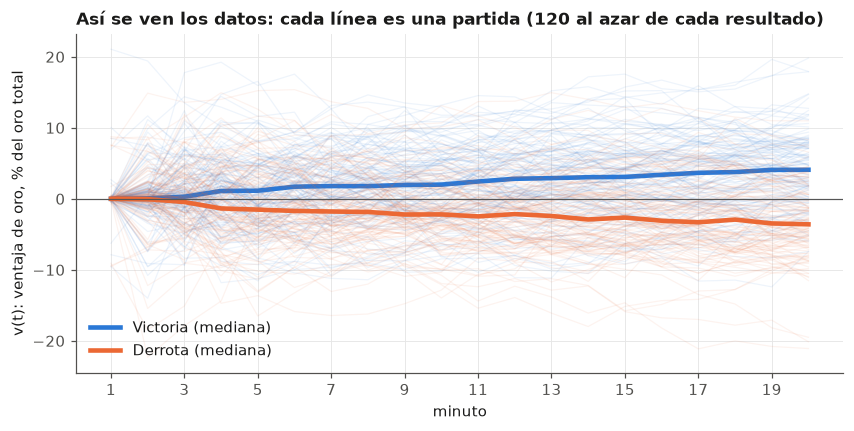

In [3]:
fig, ax = plt.subplots(figsize=(9, 4))
minutos = np.arange(1, T + 1)
rng = np.random.default_rng(SEMILLA)
for res, color in COL_RES.items():
    filas = X[resultado == res]
    for i in rng.choice(len(filas), 120, replace=False):
        ax.plot(minutos, filas[i], color=color, alpha=0.08, lw=0.8)
    ax.plot(minutos, np.median(filas, axis=0), color=color, lw=3, label=f"{res} (mediana)")
ax.axhline(0, color="#555", lw=0.8)
ax.set_xticks(minutos[::2])
ax.set_xlabel("minuto")
ax.set_ylabel("v(t): ventaja de oro, % del oro total")
ax.set_title("Así se ven los datos: cada línea es una partida (120 al azar de cada resultado)")
ax.legend(loc="lower left")
plt.show()

Cada partida es una curva; en 20 dimensiones no se puede ver la nube completa de 1,132 puntos.
Las medianas ya sugieren que las victorias se separan de las derrotas poco a poco, minuto a
minuto, pero hay muchísimo traslape. Los algoritmos de reducción de dimensionalidad proyectan
cada curva a un punto en 2D para ver esa nube completa.

**Sobre el preprocesamiento:** las 20 variables están en la **misma unidad** (% del oro total), así
que se centran pero **no se estandarizan**. Estandarizar le daría el mismo peso al minuto 1, donde
casi todas las partidas están en 0 y lo que varía es ruido, que al minuto 20, donde está la
información. PCA centra los datos por su cuenta; t-SNE y UMAP trabajan con distancias, que ya
tienen sentido en esta unidad.

In [4]:
def dispersion(ax, Z, colores, titulo, etiquetas, fondo=None, s=10):
    '''Dibuja Z (n × 2) coloreado por `etiquetas`; `fondo` = máscara de puntos en gris tenue.'''
    if fondo is not None:
        ax.scatter(Z[fondo, 0], Z[fondo, 1], s=s, color="#d9d9d9", lw=0, label="Victoria (fondo)")
    for nombre, color in colores.items():
        m = etiquetas == nombre
        if m.any():
            ax.scatter(Z[m, 0], Z[m, 1], s=s, color=color, lw=0, alpha=0.75,
                       label=f"{nombre} ({m.sum()})")
    ax.set_title(titulo)
    ax.legend(loc="best", fontsize=8, markerscale=1.8)


def dos_paneles(Z, metodo, ejes=("componente 1", "componente 2")):
    '''Panel izquierdo: resultado. Panel derecho: las derrotas por forma de perder.'''
    fig, (a, b) = plt.subplots(1, 2, figsize=(12, 5))
    dispersion(a, Z, COL_RES, f"{metodo}: victorias y derrotas", resultado)
    dispersion(b, Z, COL_ARQ, f"{metodo}: las derrotas, por forma de perder", forma,
               fondo=~es_derrota)
    for ax in (a, b):
        ax.set_xlabel(ejes[0]); ax.set_ylabel(ejes[1])
    plt.tight_layout()
    plt.show()


resumen = {}                                             # métricas para comparar al final


def evaluar(nombre, Z, segundos):
    '''Qué tan fiel es el mapa a los vecindarios originales y qué tan separados quedan los resultados.'''
    resumen[nombre] = {
        "confiabilidad (k=10)": trustworthiness(X, Z, n_neighbors=10),
        "silueta victoria/derrota": silhouette_score(Z, resultado),
        "segundos": segundos,
    }

## 2. PCA · Análisis de componentes principales

PCA busca las direcciones (combinaciones lineales de los 20 minutos) donde los datos varían más.
Es **lineal** y **no usa las etiquetas**. Su gran ventaja es que se puede interpretar: cada
componente es una "forma de curva", y se puede graficar qué peso le da a cada minuto.

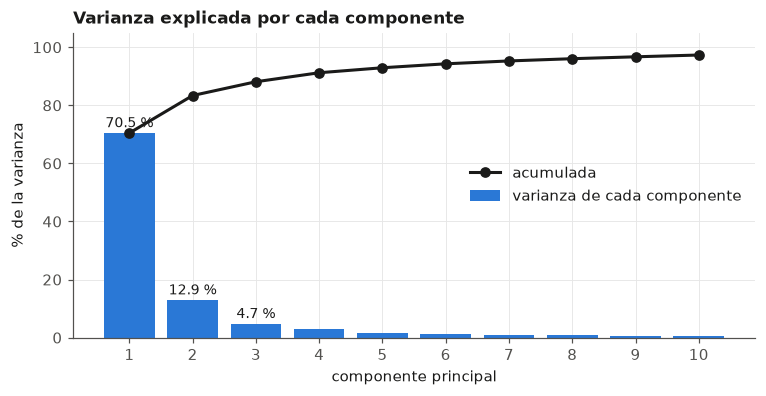

PC1 explica el 70.5%; PC1+PC2, el 83.4%; se necesitan 4 componentes para el 90 %.


In [5]:
t0 = time.time()
pca = PCA(random_state=SEMILLA).fit(X)
Z_pca = pca.transform(X)[:, :2]
evaluar("PCA", Z_pca, time.time() - t0)

var = pca.explained_variance_ratio_
acum = np.cumsum(var)
fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(np.arange(1, 11), var[:10] * 100, color="#2a78d6", label="varianza de cada componente")
ax.plot(np.arange(1, 11), acum[:10] * 100, "o-", color="#1a1a19", label="acumulada")
for i in range(3):
    ax.text(i + 1, var[i] * 100 + 2, f"{var[i] * 100:.1f} %", ha="center", fontsize=9)
ax.set_xticks(range(1, 11))
ax.set_xlabel("componente principal")
ax.set_ylabel("% de la varianza")
ax.set_ylim(0, 105)
ax.set_title("Varianza explicada por cada componente")
ax.legend(loc="center right")
plt.show()
print(f"PC1 explica el {var[0]:.1%}; PC1+PC2, el {acum[1]:.1%}; "
      f"se necesitan {int(np.argmax(acum >= 0.90)) + 1} componentes para el 90 %.")

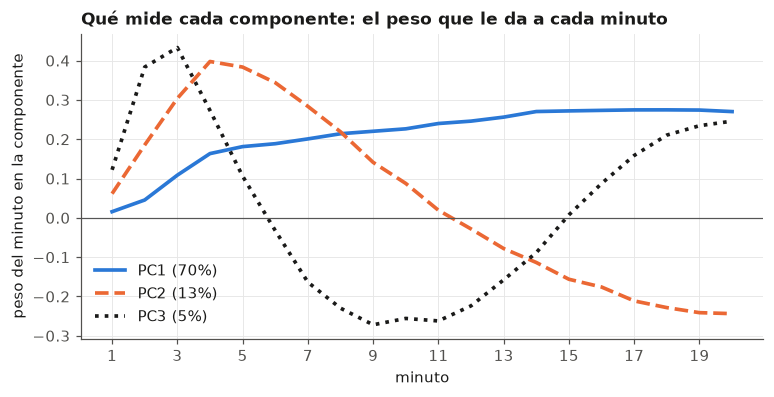

Correlación de PC1 con la ventaja promedio de los 20 minutos: 0.994
Correlación de PC2 con (ventaja promedio de los minutos 1-8) − (de los minutos 15-20): 0.834


In [6]:
fig, ax = plt.subplots(figsize=(8, 3.6))
estilos = ["-", "--", ":"]
for i in range(3):
    ax.plot(minutos, pca.components_[i], estilos[i], lw=2.4, color=["#2a78d6", "#eb6834", "#1a1a19"][i],
            label=f"PC{i + 1} ({var[i]:.0%})")
ax.axhline(0, color="#555", lw=0.8)
ax.set_xticks(minutos[::2])
ax.set_xlabel("minuto")
ax.set_ylabel("peso del minuto en la componente")
ax.set_title("Qué mide cada componente: el peso que le da a cada minuto")
ax.legend()
plt.show()
puntaje = pca.transform(X)
print(f"Correlación de PC1 con la ventaja promedio de los 20 minutos: "
      f"{np.corrcoef(puntaje[:, 0], X.mean(axis=1))[0, 1]:.3f}")
print(f"Correlación de PC2 con (ventaja promedio de los minutos 1-8) − (de los minutos 15-20): "
      f"{np.corrcoef(puntaje[:, 1], X[:, :8].mean(axis=1) - X[:, 14:].mean(axis=1))[0, 1]:.3f}")

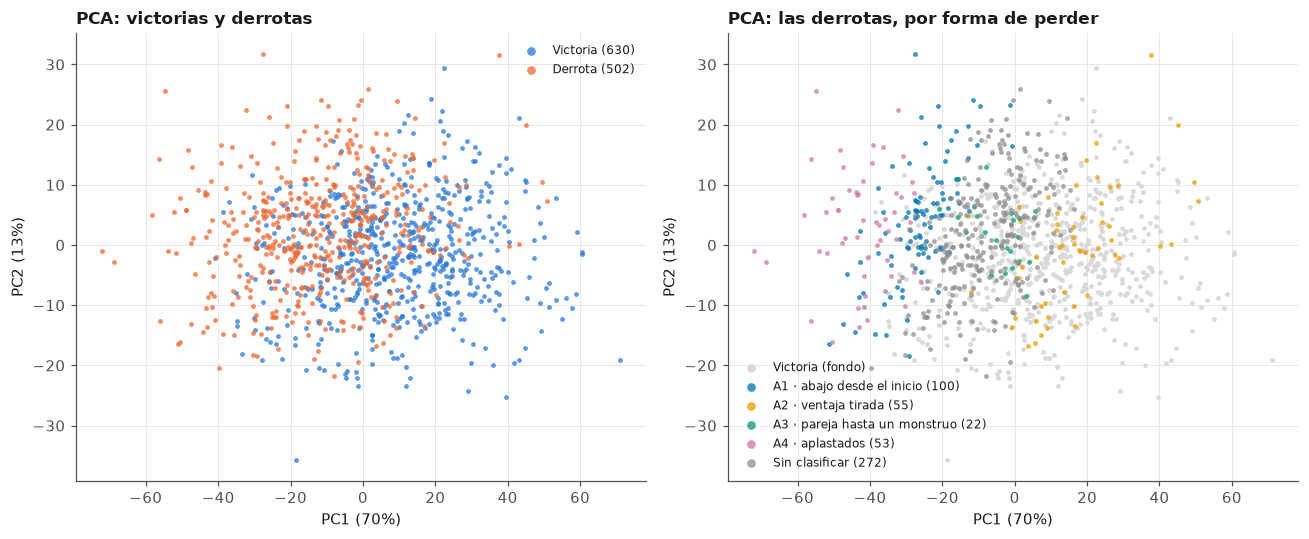

In [7]:
dos_paneles(Z_pca, "PCA", ejes=(f"PC1 ({var[0]:.0%})", f"PC2 ({var[1]:.0%})"))

**Lectura del PCA**

- **Dos componentes guardan el 83.4 % de la varianza.** La nube de 20 dimensiones es casi plana:
  los 20 minutos están tan correlacionados entre sí (la ventaja de un minuto se parece mucho a la
  del siguiente) que un mapa lineal en 2D ya la representa bien.
- **PC1 (70.5 %) es la ventaja promedio de la partida.** Le da peso positivo a todos los minutos,
  más a los tardíos, y su puntaje tiene correlación **0.994** con la ventaja promedio de los 20
  minutos. Pesa más el final porque la ventaja se acumula: al minuto 20 las partidas están mucho
  más dispersas que al minuto 3.
- **PC2 (12.9 %) contrasta el inicio con el final:** pesos positivos hasta el minuto 10 (máximo
  en el 4) y negativos desde el 12 (correlación **0.834** con "ventaja de los minutos 1–8 menos la
  de los minutos 15–20"). Arriba quedan las partidas que empezaron mejor de lo que terminaron;
  abajo, las que se fueron recuperando.
- **PC3 (4.7 %)** tiene un pico muy temprano (minutos 2–4), un valle a mitad (7–13) y vuelve a
  subir: captura partidas con un arranque distinto a su desarrollo. Ya es una fracción pequeña.

**En el mapa**, las victorias quedan a la derecha y las derrotas a la izquierda, pero **sin un
hueco entre ellas**: es una sola nube con un gradiente, no dos grupos. Las formas de perder se
ordenan sobre PC1: **A4** (aplastados) en el extremo izquierdo, **A1** (abajo desde el inicio)
junto a ellas, **sin clasificar** en el centro, y **A2** (ventaja tirada) **del lado de las
victorias**.

## 3. LDA · Análisis discriminante lineal

LDA también es **lineal**, pero es **supervisado**: usa las etiquetas para buscar las direcciones
que mejor **separan las clases**, no las de mayor varianza. Con $k$ clases da a lo más $k-1$ ejes.

Se hacen dos versiones:

1. **Resultado** (2 clases → 1 eje): ¿qué combinación de los 20 minutos separa mejor victorias de
   derrotas? Además se mide, con validación cruzada, qué tan bien predice el resultado esa sola
   combinación.
2. **Seis clases** (victoria + las cinco formas de perder → hasta 5 ejes): un mapa 2D supervisado,
   comparable con los otros métodos.

**Advertencia:** las formas de perder se definieron con reglas sobre estas mismas curvas, así que
es esperable que LDA las separe en parte; lo interesante es *cuánto* se traslapan y dónde cae
"sin clasificar".

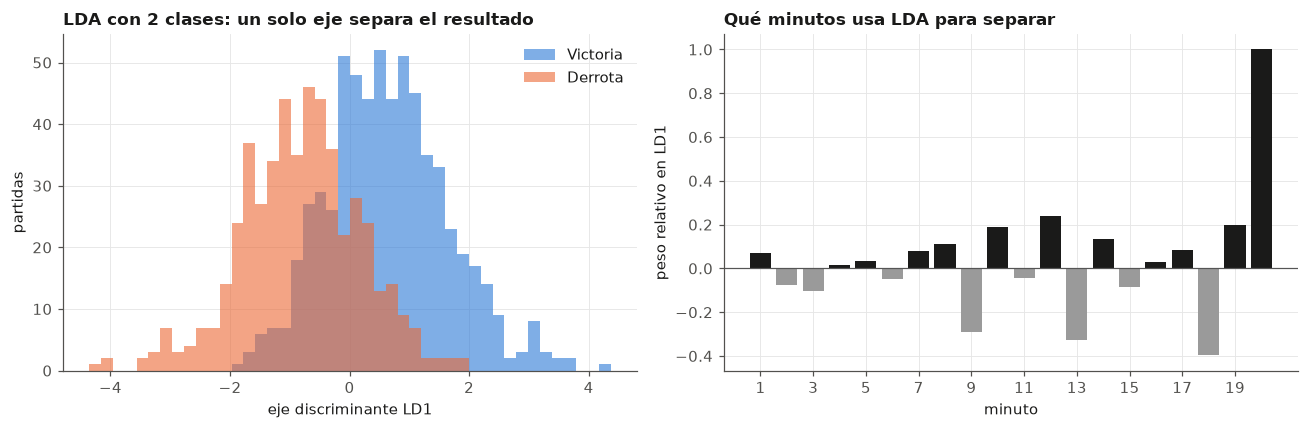

Exactitud de LDA para predecir el resultado con los primeros 20 minutos (validación cruzada, 5 pliegues): 76.4% ± 1.0%
Referencia: siempre decir 'victoria' acierta el 55.7%.
Referencia: decir 'victoria' si v(20) > 0 acierta el 76.8%.


In [8]:
t0 = time.time()
lda_res = LDA(n_components=1).fit(X, resultado)
z = lda_res.transform(X)[:, 0]
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
acierto = cross_val_score(LDA(), X, resultado, cv=cv)

fig, (a, b) = plt.subplots(1, 2, figsize=(12, 4))
bins = np.linspace(z.min(), z.max(), 45)
for res, color in COL_RES.items():
    a.hist(z[resultado == res], bins=bins, color=color, alpha=0.6, label=res)
a.set_xlabel("eje discriminante LD1")
a.set_ylabel("partidas")
a.set_title("LDA con 2 clases: un solo eje separa el resultado")
a.legend()
coef = lda_res.scalings_[:, 0]
b.bar(minutos, coef / np.abs(coef).max(), color=np.where(coef >= 0, "#1a1a19", "#9a9a9a"))
b.axhline(0, color="#555", lw=0.8)
b.set_xticks(minutos[::2])
b.set_xlabel("minuto")
b.set_ylabel("peso relativo en LD1")
b.set_title("Qué minutos usa LDA para separar")
plt.tight_layout()
plt.show()
print(f"Exactitud de LDA para predecir el resultado con los primeros {T} minutos "
      f"(validación cruzada, 5 pliegues): {acierto.mean():.1%} ± {acierto.std():.1%}")
print(f"Referencia: siempre decir 'victoria' acierta el {np.mean(resultado == 'Victoria'):.1%}.")
print(f"Referencia: decir 'victoria' si v(20) > 0 acierta el "
      f"{np.mean((X[:, -1] > 0) == (resultado == 'Victoria')):.1%}.")

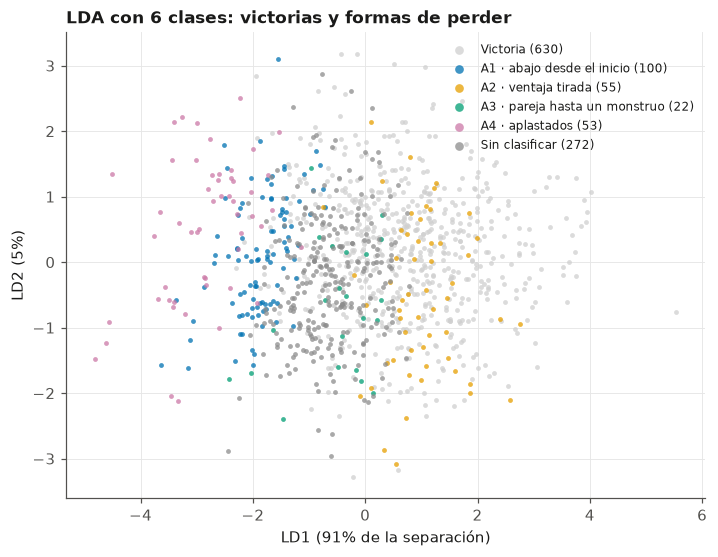

Exactitud de LDA para reconocer la forma de perder (solo derrotas, validación cruzada): 75.9% ± 3.1%
Referencia: siempre decir 'sin clasificar' acierta el 54.2%.


In [9]:
clase6 = np.where(es_derrota, forma, "Victoria").astype(str)
t0 = time.time()
lda6 = LDA(n_components=2).fit(X, clase6)
Z_lda = lda6.transform(X)
evaluar("LDA", Z_lda, time.time() - t0)
acierto6 = cross_val_score(LDA(), X[es_derrota], forma[es_derrota].astype(str), cv=cv)

colores6 = {"Victoria": "#cfcfcf", **COL_ARQ}
fig, ax = plt.subplots(figsize=(7.5, 5.5))
dispersion(ax, Z_lda, colores6, "LDA con 6 clases: victorias y formas de perder", clase6)
ax.set_xlabel(f"LD1 ({lda6.explained_variance_ratio_[0]:.0%} de la separación)")
ax.set_ylabel(f"LD2 ({lda6.explained_variance_ratio_[1]:.0%})")
plt.show()
print(f"Exactitud de LDA para reconocer la forma de perder (solo derrotas, validación cruzada): "
      f"{acierto6.mean():.1%} ± {acierto6.std():.1%}")
print(f"Referencia: siempre decir 'sin clasificar' acierta el "
      f"{np.mean(forma[es_derrota] == 'Sin clasificar'):.1%}.")

**Lectura del LDA**

- **Con 2 clases**, el eje discriminante predice el resultado con **76.4 %** de exactitud
  (validación cruzada), contra 55.7 % de decir siempre "victoria". Los histogramas se traslapan
  mucho: una cuarta parte de las partidas cae del lado equivocado con solo los primeros 20 minutos.
- **LDA se apoya sobre todo en el minuto 20.** Tiene sentido: la ventaja se acumula, así que el
  último minuto observado resume casi todo lo anterior. De hecho, la regla más simple, "decir
  victoria si v(20) > 0", acierta el **76.8 %**, lo mismo que LDA (76.4 %; la regla no ajusta nada,
  así que no necesita validación cruzada): **combinar los 20 minutos no agrega información sobre el
  último**. Al menos de forma lineal, el *camino* que siguió la ventaja no ayuda a predecir el
  resultado; lo que cuenta es dónde va al minuto 20. Los pesos que alternan de signo
  entre minutos vecinos (9 negativo, 10 positivo; 12 positivo, 13 negativo) **no** se deben leer
  minuto por minuto: como los minutos consecutivos están casi duplicados, LDA puede repartir el
  peso entre ellos de muchas maneras equivalentes.
- **Con 6 clases**, LD1 concentra el **91 %** de la separación y vuelve a ser, en la práctica, el
  eje de la ventaja: A4 en el extremo izquierdo, luego A1, *sin clasificar* en el centro y A2 entre
  las victorias. LD2 (5 %) apenas aporta. Reconoce la forma de perder con **75.9 %** de exactitud
  contra 54.2 % de la referencia; A3 (22 partidas) queda dispersa, porque su regla depende de un
  monstruo del rival y no solo de la curva de oro.

Esta separación de las formas de perder **no es un hallazgo**, es una comprobación de
consistencia: las reglas que las definen se aplican sobre estas mismas curvas. La advertencia
vale también para los paneles "por forma de perder" de los demás métodos.

## 4. t-SNE · *t-distributed Stochastic Neighbor Embedding*

t-SNE es **no lineal** y **no supervisado**. No busca ejes: coloca los puntos en 2D intentando que
las partidas que eran **vecinas** en 20 dimensiones sigan siendo vecinas. Es muy bueno mostrando
grupos locales, pero tiene reglas de lectura:

- los ejes **no significan nada** (no hay "componente 1");
- el **tamaño** de un grupo y la **distancia entre grupos** no se pueden interpretar;
- el resultado depende de la **perplejidad** (cuántos vecinos "mira" cada punto) y de la semilla.

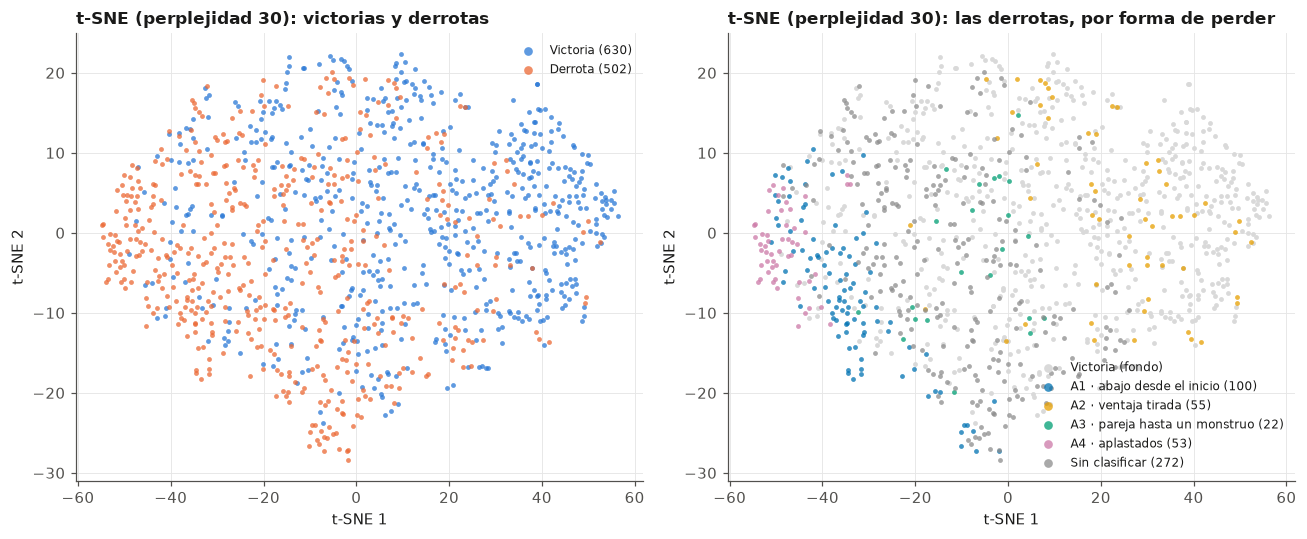

In [10]:
t0 = time.time()
Z_tsne = TSNE(n_components=2, perplexity=30, init="pca", learning_rate="auto",
              random_state=SEMILLA).fit_transform(X)
evaluar("t-SNE", Z_tsne, time.time() - t0)
dos_paneles(Z_tsne, "t-SNE (perplejidad 30)", ejes=("t-SNE 1", "t-SNE 2"))

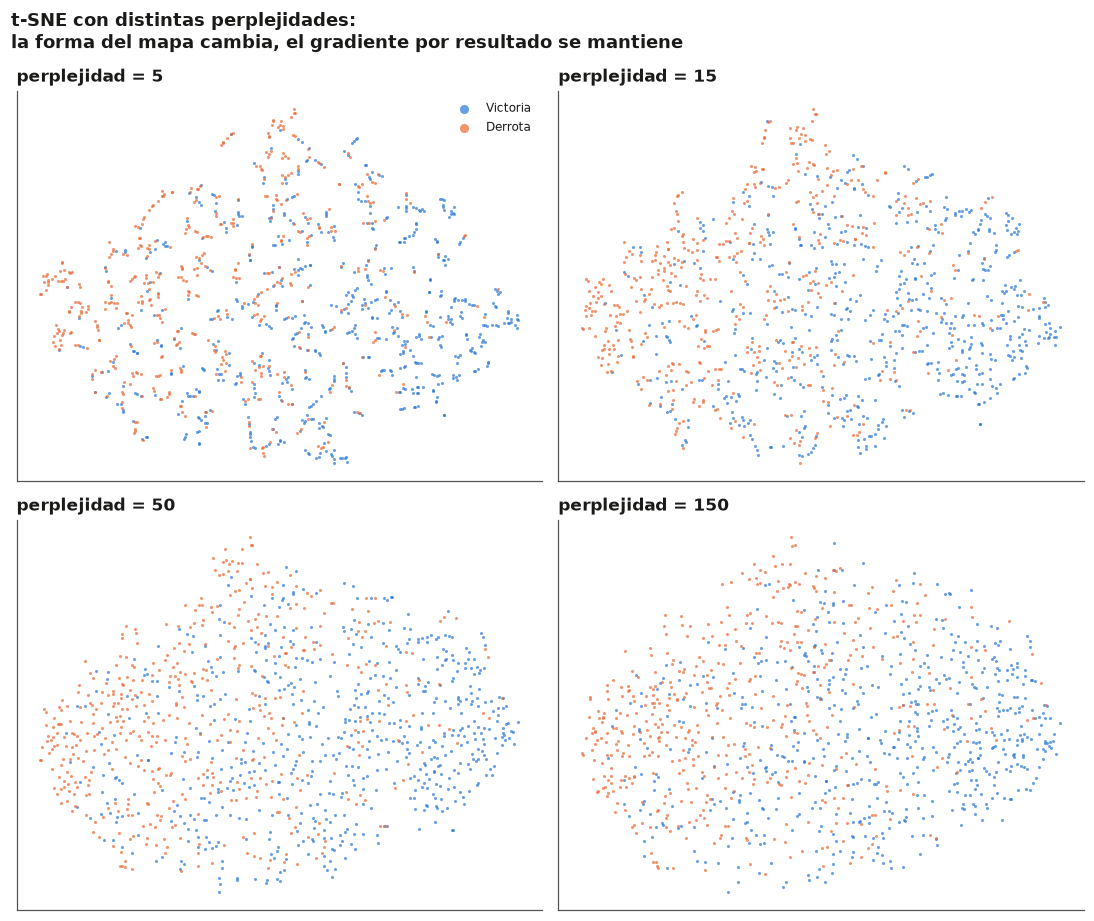

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
axes = axes.ravel()
for ax, perp in zip(axes, (5, 15, 50, 150)):
    Z = TSNE(n_components=2, perplexity=perp, init="pca", learning_rate="auto",
             random_state=SEMILLA).fit_transform(X)
    for res, color in COL_RES.items():
        m = resultado == res
        ax.scatter(Z[m, 0], Z[m, 1], s=4, color=color, lw=0, alpha=0.7, label=res)
    ax.set_title(f"perplejidad = {perp}")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8)
fig.suptitle("t-SNE con distintas perplejidades:\nla forma del mapa cambia, el gradiente por resultado se mantiene",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura del t-SNE**

- **No aparecen islas.** Aun siendo el método que más tiende a "inventar" grupos, t-SNE dibuja
  una sola nube con un gradiente de izquierda (derrotas) a derecha (victorias) y una franja
  central donde se mezclan.
- **Lo que sí aparece es un borde denso de derrotas**: A4 forma un racimo compacto en el extremo
  izquierdo y A1 queda junto a él. Son las partidas más parecidas entre sí: curvas que caen
  pronto y no se recuperan. A2 queda dispersa entre las victorias.
- **La perplejidad cambia la textura, no la conclusión.** Con perplejidad 5, cada punto solo
  "mira" a unos pocos vecinos y el mapa se rompe en grumos pequeños, más mezclados; con 50 o 150 la
  nube se vuelve más lisa. En las cuatro el gradiente por resultado se mantiene y en ninguna
  aparece una frontera limpia. Los grumos de perplejidad 5 son un efecto del parámetro, no grupos
  reales de partidas.

## 5. UMAP · *Uniform Manifold Approximation and Projection*

UMAP es **no lineal** y **no supervisado**, como t-SNE: construye un grafo de vecinos en 20
dimensiones y busca un mapa en 2D con un grafo parecido. Suele ser más rápido y conservar algo más
de la estructura **global** (el orden entre regiones). Sus dos parámetros principales son
`n_neighbors` (local contra global) y `min_dist` (qué tan apretados quedan los puntos).

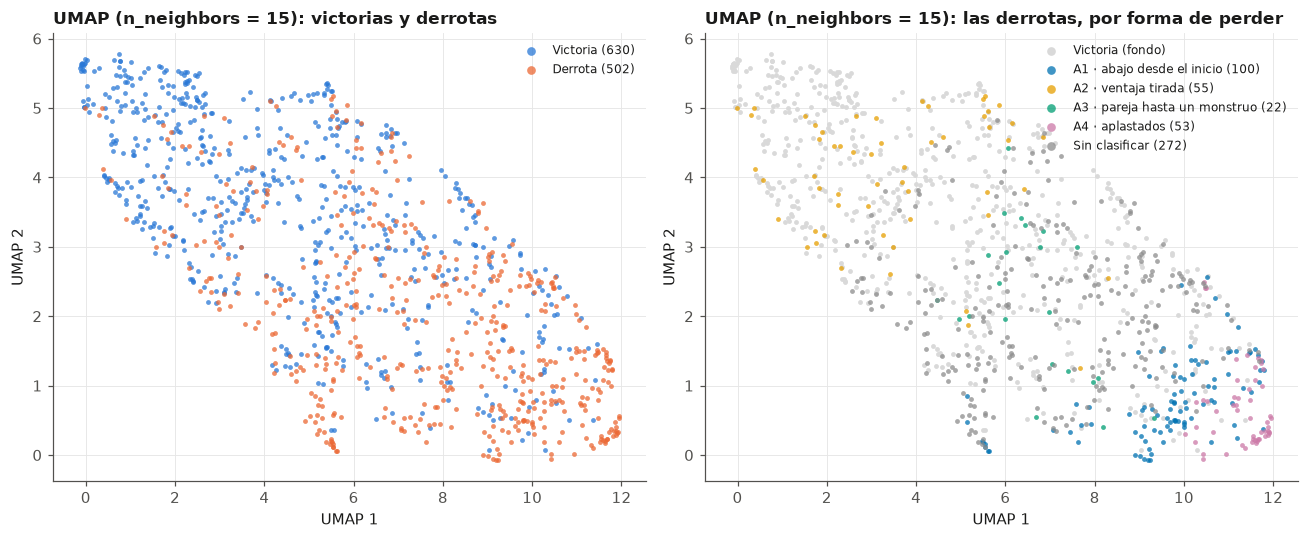

In [12]:
t0 = time.time()
Z_umap = umap.UMAP(n_components=2, n_neighbors=15, min_dist=0.1,
                   random_state=SEMILLA).fit_transform(X)
evaluar("UMAP", Z_umap, time.time() - t0)
dos_paneles(Z_umap, "UMAP (n_neighbors = 15)", ejes=("UMAP 1", "UMAP 2"))

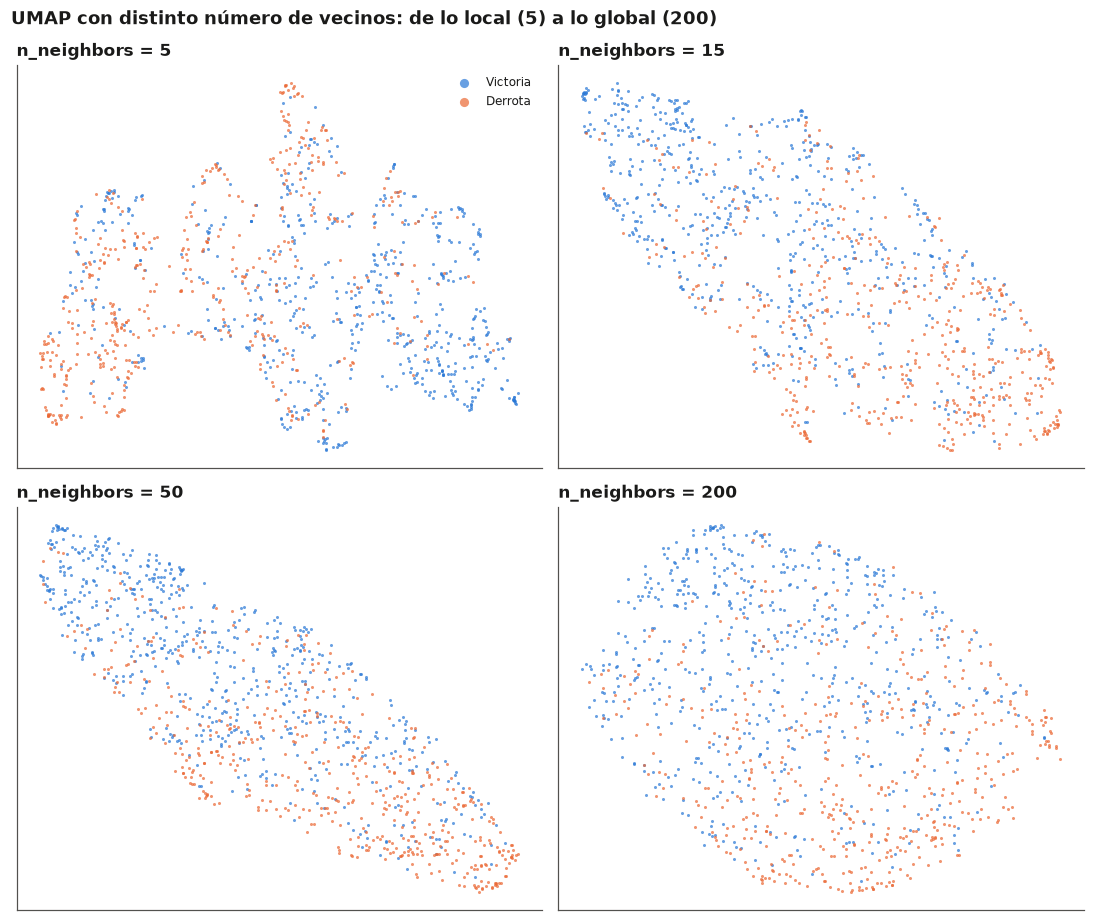

In [13]:
fig, axes = plt.subplots(2, 2, figsize=(10, 8.5))
axes = axes.ravel()
for ax, k in zip(axes, (5, 15, 50, 200)):
    Z = umap.UMAP(n_components=2, n_neighbors=k, min_dist=0.1, random_state=SEMILLA).fit_transform(X)
    for res, color in COL_RES.items():
        m = resultado == res
        ax.scatter(Z[m, 0], Z[m, 1], s=4, color=color, lw=0, alpha=0.7, label=res)
    ax.set_title(f"n_neighbors = {k}")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=3, fontsize=8)
fig.suptitle("UMAP con distinto número de vecinos: de lo local (5) a lo global (200)",
             x=0.01, ha="left", fontweight="bold")
plt.tight_layout()
plt.show()

**Lectura del UMAP**

- Con `n_neighbors = 15`, UMAP acomoda las partidas en **una banda alargada**: victorias en un
  extremo, derrotas en el otro y mezcla en medio. El orden a lo largo de la banda es, otra vez,
  la ventaja de oro; UMAP llega a él sin usar etiquetas y sin ser lineal.
- En el panel de formas de perder, **A4 y A1 ocupan la punta** de la banda, *sin clasificar* el
  tramo medio, y **A2 sube hasta la zona de las victorias**: el mismo orden que en PCA, t-SNE y
  LDA.
- **El número de vecinos sí cambia el mapa.** Con 5 vecinos UMAP solo ve vecindarios muy
  pequeños y parte la nube en "islas" que no existen en los otros métodos ni con más vecinos: son
  artefactos locales. Con 15 y 50 aparece la banda, y con 200 la nube se redondea porque cada punto
  ya "ve" casi una quinta parte de los datos. Ninguna configuración separa victorias de derrotas
  en grupos distintos.

## 6. Comparación de los cuatro métodos

Los cuatro mapas lado a lado, con las mismas partidas y los mismos colores. Para no comparar solo
a ojo se calculan dos medidas:

- **Confiabilidad** (*trustworthiness*, de 0 a 1): qué tanto los 10 vecinos más cercanos de cada
  partida en el mapa 2D eran también vecinos en las 20 dimensiones. Mide si el mapa "inventa"
  vecindarios.
- **Silueta por resultado** (de −1 a 1): qué tan separadas quedan las victorias de las derrotas en
  el mapa. Cerca de 0 significa que se traslapan.

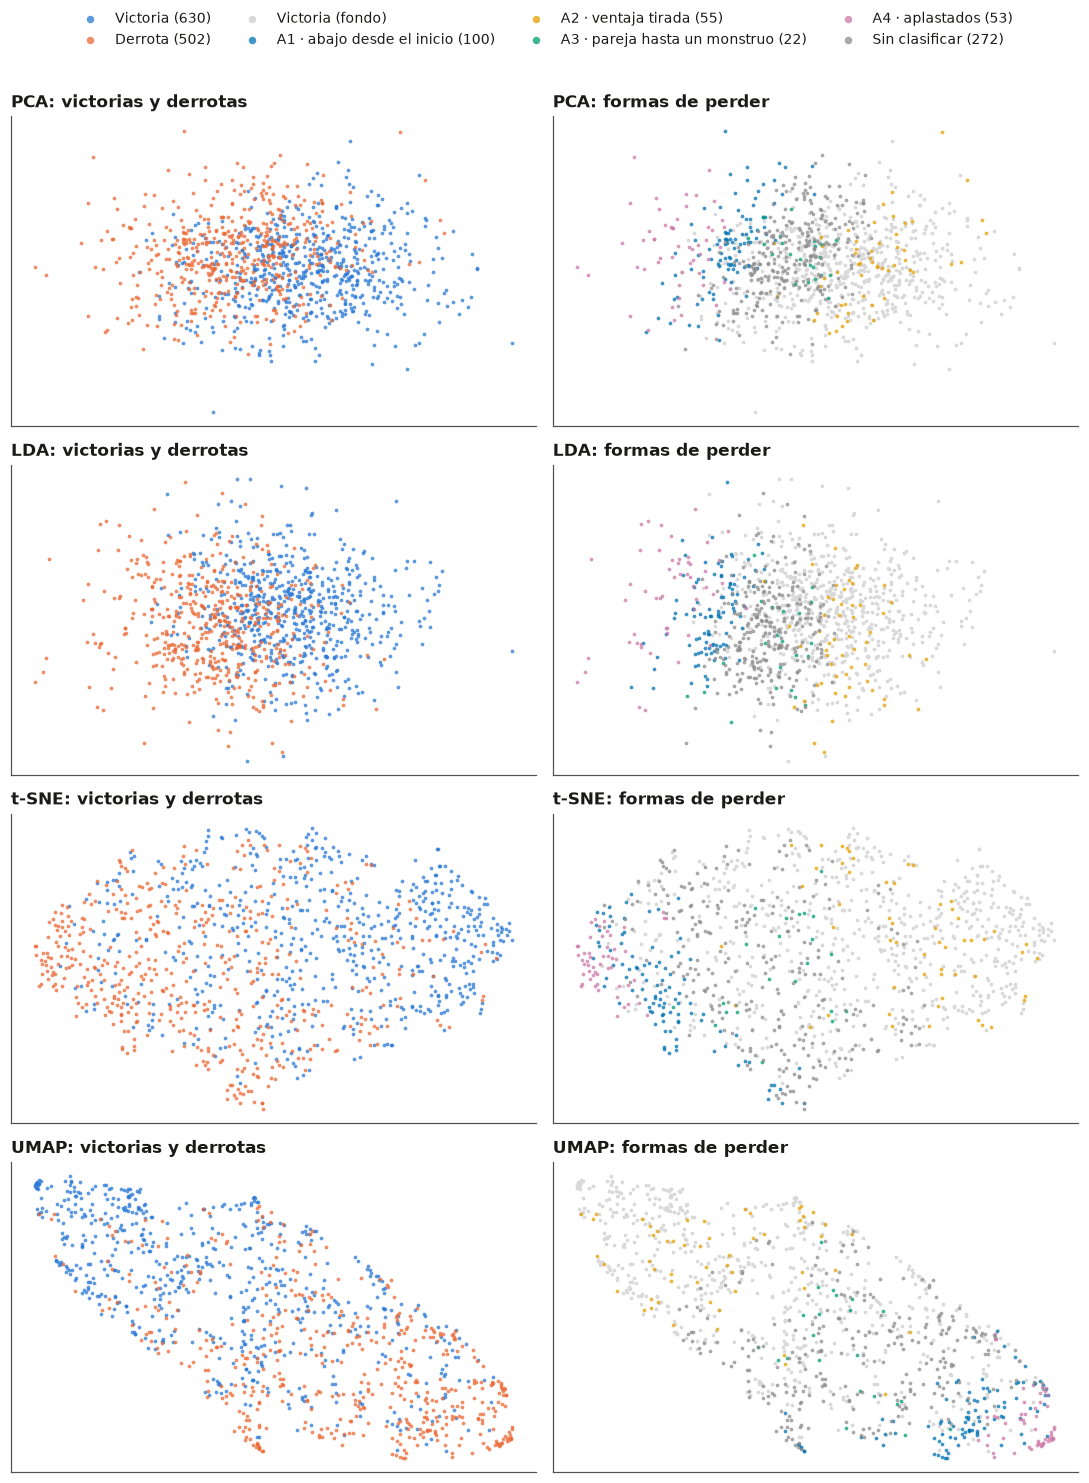

,confiabilidad (k=10),silueta victoria/derrota,segundos
PCA,0.946,0.152,0.0
LDA,0.805,0.174,0.0
t-SNE,0.976,0.162,8.5
UMAP,0.961,0.166,22.3


In [14]:
mapas = {"PCA": Z_pca, "LDA": Z_lda, "t-SNE": Z_tsne, "UMAP": Z_umap}
fig, axes = plt.subplots(4, 2, figsize=(10, 13.5))
for i, (nombre, Z) in enumerate(mapas.items()):
    dispersion(axes[i, 0], Z, COL_RES, f"{nombre}: victorias y derrotas", resultado, s=6)
    dispersion(axes[i, 1], Z, COL_ARQ, f"{nombre}: formas de perder", forma, fondo=~es_derrota, s=6)
    for ax in axes[i]:
        ax.set_xticks([]); ax.set_yticks([])
        ax.get_legend().remove()
h1, l1 = axes[0, 0].get_legend_handles_labels()          # una sola leyenda arriba, fuera de los puntos
h2, l2 = axes[0, 1].get_legend_handles_labels()
fig.legend(h1 + h2, l1 + l2, loc="upper center", ncol=4, markerscale=2, fontsize=9)
plt.tight_layout(rect=(0, 0, 1, 0.95))
plt.show()

tabla = pd.DataFrame(resumen).T.round({"confiabilidad (k=10)": 3, "silueta victoria/derrota": 3,
                                        "segundos": 1})
tabla

**Lectura de la comparación**

- **Los cuatro mapas cuentan la misma historia**: una sola nube ordenada por la ventaja de oro,
  con victorias en un extremo, derrotas en el otro y una zona grande de mezcla. La silueta por
  resultado queda entre **0.15 y 0.17** en los cuatro: traslape en todos.
- **El orden de confiabilidad es esperable, no un veredicto.** t-SNE (0.976) queda primero porque
  optimiza justamente eso, conservar los vecinos cercanos; UMAP (0.961) lo sigue. LDA (0.805) queda
  último **por diseño**: descarta la varianza que no sirve para separar las clases, así que
  deforma los vecindarios.
- **La silueta de LDA (0.174) no es comparable** con las otras: LDA vio las etiquetas para armar
  su mapa. Aun así, apenas supera a los métodos que no las vieron.
- **El dato más útil es el de PCA: 0.946 con un mapa lineal** que tarda una fracción de segundo.
  Como la nube ya es casi plana (83.4 % de la varianza en dos componentes), los métodos no lineales
  ganan poco aquí, y PCA tiene la ventaja de que sus ejes se pueden leer (ventaja promedio;
  inicio contra final).

## 7. Conclusiones

**¿Las victorias y las derrotas forman grupos separados?** No. En los cuatro métodos las 1,132
partidas forman **un continuo** ordenado por la ventaja de oro: victorias en un extremo, derrotas
en el otro y una franja ancha donde se mezclan. Ningún método, lineal o no lineal, supervisado o
no, encuentra una frontera limpia; la silueta por resultado no pasa de 0.17 y el mejor
clasificador lineal se equivoca en casi una de cada cuatro partidas con los primeros 20 minutos.

**¿Las formas de perder aparecen como grupos?** Tampoco como grupos aislados: aparecen como
**regiones del mismo continuo**. A4 (aplastados) y A1 (abajo desde el inicio) ocupan el extremo de
las derrotas; *sin clasificar* el centro. Que los cuatro métodos coincidan en ese orden es una
comprobación de consistencia, no un descubrimiento: las reglas que las definen usan estas mismas
curvas.

**Lo que conecta con la pregunta del proyecto** (*¿en qué minuto se perdió la partida?*): **las
derrotas A2, "ventaja tirada", caen entre las victorias en los cuatro mapas.** Hasta el minuto 20
esas partidas se ven ganadas; se perdieron *después* de la ventana que ven estos mapas. Es la misma
idea a la que llega el proyecto por otro camino: muchas derrotas no se deciden en los primeros 20
minutos.

**Sobre los métodos:**

| Método | Tipo | Qué aporta aquí | Cuidado |
|---|---|---|---|
| PCA | lineal, no supervisado | ejes interpretables (ventaja promedio; inicio contra final); 83 % de la varianza en 2D | solo ve relaciones lineales |
| LDA | lineal, supervisado | mide cuánto separa la mejor combinación lineal (76 % de exactitud, igual que mirar solo el minuto 20) | usa las etiquetas; su mapa no sirve para "descubrir" grupos |
| t-SNE | no lineal, no supervisado | la mayor fidelidad local; muestra el borde denso de A4/A1 | tamaños y distancias entre regiones no se interpretan; depende de la perplejidad |
| UMAP | no lineal, no supervisado | conserva el orden global como una banda | con pocos vecinos fabrica islas |

**Límite:** los mapas solo ven los primeros 20 minutos, para que todas las partidas tengan las
mismas dimensiones. Lo que pasa después (donde se deciden muchas derrotas A2) queda fuera de esta
representación.